# Tutorial 11: Predicting Capacitance Matrices from a GDS file using ML

In our latest paper, ["QCap: a physics-corrected graph neural network for the capacitance matrix of any planar superconducting device layout"](https://lfl-lab.github.io/SQuADDS/ml-paper/paper/), we have shown how we developed a capacitance foundation model that can be used to predict the Maxwell capacitance matrix of ANY planar superconducting device layout on ANY substrate. The results are within 1% agreement with its counterpart accurate Q3D simulation and run in seconds on a CPU. The [paper page](https://lfl-lab.github.io/SQuADDS/ml-paper/) also has videos and more tutorials.

**Note:** the models need the optional ML extra, `pip install "squadds[ml]"`, and the GDS export from quantum-metal needs the `gds` extra, `pip install "squadds[gds]"`.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

## Why the Maxwell capacitance matrix?

Capacitors are the workhorse of any superconducting processor and are structures that designers spend a lot of time optimizing layouts for. The hope of this ML model is to reduce the iteration times of device design lifecycle.

Now, as for why the Maxwell matrix, we motivate that by the following example that we will walk through in this tutorial:

Let's say we are laying out a coupler that has to talk to three qubits at once: a five-fingered star in a circular ground pocket, with a pad sitting in three of its valleys (a *multipad star*). Before we send it to the fab, we want to know:

1. the coupling capacitance between the star and each pad (it sets the coupling strength $g$),
2. the self capacitance of every island (it sets the charging energies $E_C$), and
3. the pad-to-pad capacitances we never asked for (they set the crosstalk).

All of these are entries of **one** matrix. For $N$ conductors (ground included), the charges and the voltages are related by the Maxwell capacitance matrix

$$Q_i = \sum_{j} C_{ij} V_j .$$

The diagonal entry $C_{ii} > 0$ is the self capacitance of conductor $i$ (its charge when it sits at 1 V and everything else is grounded), and the off-diagonal entries are negative, $C_{ij} = -C^{\rm mutual}_{ij} < 0$. Every signal row sums to a small non-negative number (the field lines that escape to infinity), so $C_{ii} \geq \sum_{j \neq i} |C_{ij}|$.

A circuit Hamiltonian needs every entry at once: the charging energy of island $i$ is $E_{C,i} = \frac{e^2}{2}\,(C^{-1})_{ii}$, where $C$ is the signal block (ground removed), and an inverse mixes every entry of the matrix. One two-terminal simulation per pair does not give us that.

Throughout SQuADDS the matrix is in **fF**, with **ground first** (row and column 0, named `G`).

## Setting up

We'll use quantum-metal without its GUI, so let's tell it that before importing anything.

In [2]:
import os

os.environ["QISKIT_METAL_HEADLESS"] = "1"

import warnings

warnings.filterwarnings("ignore")

In [3]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

We'll keep every file we write in one folder next to this notebook.

In [4]:
work = Path("tutorial11_files")
work.mkdir(exist_ok=True)

## Drawing a multipad star

`SQuADDS` includes the quantum-metal component for every family of the planar capacitance dataset used to train the model. The multipad star is `GeneralizedCapStar`: `pad_enables` switches a pad on (`1`) or off (`0`) in each valley, and the star has a short feed line (`cpw_length`) to the north.

In [5]:
from qiskit_metal import designs

from squadds.components import GeneralizedCapStar

Importing SQuADDS also loads scqubits, which switches the inline figures of the notebook to vector formats. Let's switch them back to PNG so the plots stay light.

In [6]:
from matplotlib_inline.backend_inline import set_matplotlib_formats

set_matplotlib_formats("png")

In [7]:
star_options = dict(
    n_points="5",
    star_outer_radius="136.4um",
    star_inner_radius="59.04um",
    tip_radius="2.73um",
    valley_radius="8.8um",
    star_rotation="54",
    gap="18um",
    pocket_radius="160.35um",
    pad_side_gap="6um",
    pad_enables="1,1,0,1,0",
    cpw_length="30um",
    cpw_width="10um",
    cpw_gap="6um",
)

In [8]:
star_design = designs.DesignPlanar({}, overwrite_enabled=True)
GeneralizedCapStar(star_design, "star", options=star_options)
star_design.rebuild()

Now let's export it with `squadds.layouts.qmetal_gds`. With `include_ground_domain=True` it writes the layer convention the models read: a square ground plane on 1/0 that reaches 169 µm past the metal, with the component's own etch cut out of it, and every piece of signal metal on 1/10. `minimum_ground_clearance_um` only closes the open end of the feed line (we use the CPW gap, 6 µm).

<details>
<summary><b>Using a GDS that was not drawn with SQuADDS</b></summary>

Any GDS works. `prepare_layout` and `predict` only need to know which metal is the ground and which metal are the conductors, and they take the same arguments:

| your file | what to pass |
|---|---|
| ground and conductors on other layers | `ground_layers=[(5, 0)], conductor_layers=[(6, 0), (7, 0)]` (several layers are fine) |
| ground and conductors on one layer | that layer for both; the ground is detected for you (see *Ground and conductors on one layer* below) |
| several cells in the file | `cell="name"` |
| only part of a chip | `select=[...]` (conductor indices in file order) or `select_box=(x0, y0, x1, y1)` in µm, with `margin_um` to crop the ground around them |

Metal on any other layer (labels, port markers, junctions) is not modelled. Layers you pass in `ignore_layers` are skipped silently.

`prepare_layout` also repairs what breaks the convention and tells you about it in `layout.warnings`: touching or overlapping polygons on the conductor layer become one conductor, a conductor that touches the ground is merged into the ground net, and zero-area polygons are dropped. So always plot the prepared layout before you trust a number.

</details>

In [9]:
from squadds.layouts.qmetal_gds import export_qgeometry_gds

In [10]:
star_gds = work / "multipad_star.gds"
export_qgeometry_gds(star_design, star_gds, include_ground_domain=True, minimum_ground_clearance_um=6)
star_gds

PosixPath('tutorial11_files/multipad_star.gds')

## The input GDS to the model

Since the input to the model is the GDS file, let's look at what the model sees.

`prepare_layout` reads a GDS exactly the way the predictor does: the ground is one net, and every connected body on the conductor layer is one conductor, named `C1`, `C2`, ... in file order.

In [11]:
from squadds.ml.capacitance import prepare_layout

In [12]:
star_layout = prepare_layout(star_gds)
star_layout.names

['C1', 'C2', 'C3', 'C4']

The prepared layout draws itself with `.plot()`: the ground in grey and every conductor in its own colour, named as the predictions name it.

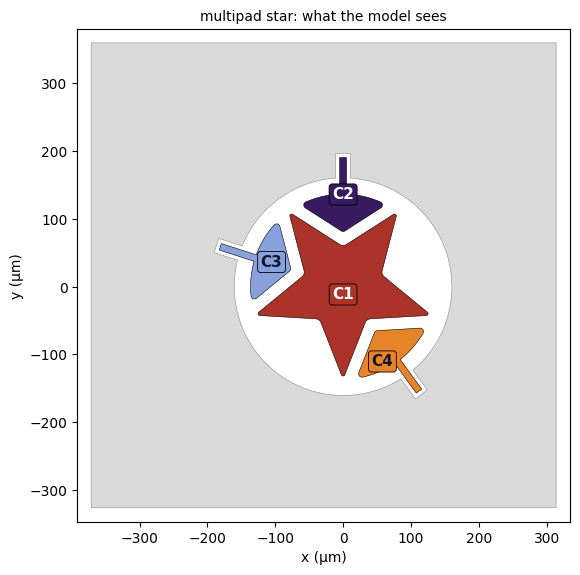

In [14]:
star_layout.plot(title="multipad star: what the model sees");

Four conductors and the ground, the star (with its feed line) and three pads. `C1`, `C2`, ... are not very telling, so let's name every body after the quantum-metal shape it overlaps the most.

In [15]:
from shapely import affinity


def name_conductors(design, layout):
    """{predictor name: quantum-metal shape name} for every conductor body (ground -> "ground")."""
    shapes = {}
    for table in ("poly", "path"):
        df = design.qgeometry.tables[table]
        for row in df[~df["subtract"].astype(bool) & ~df["helper"].astype(bool)].itertuples():
            g = row.geometry if table == "poly" else row.geometry.buffer(row.width / 2, cap_style=2)
            shapes[row.name] = affinity.scale(g, 1000, 1000, origin=(0, 0))  # Metal mm -> GDS µm
    names = {"G": "ground"}
    for name, body in zip(layout.names, layout.conductors):
        names[name] = max(shapes, key=lambda s: body.intersection(shapes[s]).area)
    return names

In [16]:
star_names = name_conductors(star_design, star_layout)
star_names

{'G': 'ground', 'C1': 'star', 'C2': 'pad_0', 'C3': 'pad_1', 'C4': 'pad_3'}

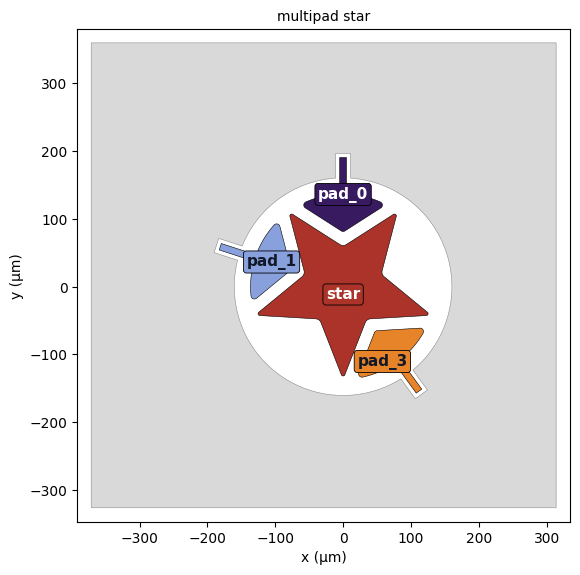

In [17]:
star_layout.plot(labels=star_names, title="multipad star");

## Predicting the capacitance matrix

The models are open-source and available on Hugging Face (`SQuADDS/QCap`). 

The `load_model` method downloads the checkpoints once, checks the sha256 of every file against the manifest shipped inside SQuADDS and refuses anything that does not match. If you already have a local copy of the models, point the environment variable `SQUADDS_CAPML_MODELS` at its folder and nothing is downloaded.

We release two models, both trained on **all** the data, and we pick one by its name:

| model | what it does | use it for |
|---|---|---|
| `QCap` (default) | solves the physics of the layout, then corrects it with the networks | every number you build on |
| `QCap-Fast` | skips the field solve: a learned surrogate stands in for the physics | screening large design spaces |

`QCap` is the released version of the main model of our paper.

In [18]:
from squadds.ml.capacitance import CapacitancePredictor, load_model

In [19]:
qcap = load_model("QCap")
qcap.name, qcap.title

('QCap',
 'QCap (~1 s): extrapolated physics R(1.5, 3) on the corrected prior + residual networks, compiled solver')

A `CapacitancePredictor` wraps a model. `threads` is the number of CPU threads per prediction (2 by default; for a given machine and thread count the results are deterministic).

In [20]:
predictor = CapacitancePredictor(qcap, threads=2)
predictor

CapacitancePredictor('QCap', threads=2)

In [21]:
res = predictor.predict(star_gds)
res

CapacitanceResult(QCap, N=5, names=['G', 'C1', 'C2', 'C3', 'C4'], total 2.45 s, checks passed)

`res.to_dataframe()` gives the matrix as a table (fF, ground first). Let's put our names on it.

In [22]:
C = res.to_dataframe().rename(index=star_names, columns=star_names)
C.round(3)

,ground,star,pad_0,pad_1,pad_3
ground,131.929,-40.698,-18.814,-18.800,-19.061
star,-40.698,70.779,-9.386,-9.364,-9.562
pad_0,-18.814,-9.386,29.278,-0.594,-0.119
pad_1,-18.800,-9.364,-0.594,29.248,-0.118
pad_3,-19.061,-9.562,-0.119,-0.118,29.215


The diagonal holds the self capacitance of every island, the off-diagonal entries are minus the mutual capacitances, and the ground row and column come first, exactly as a Q3D export would give them.

Let's plot the mutual capacitances on a log scale.

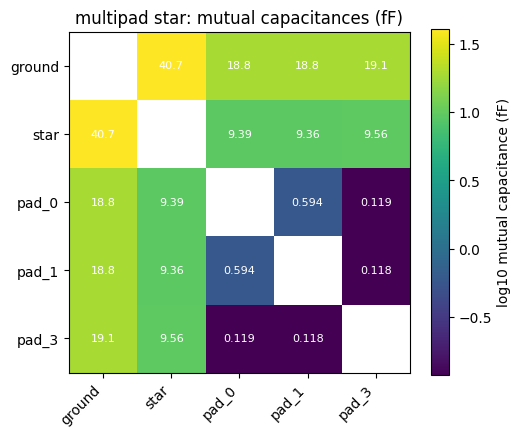

In [23]:
mut = -C.where(~np.eye(len(C), dtype=bool))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(np.log10(mut), cmap="viridis")
ax.set_xticks(range(len(C)), C.columns, rotation=45, ha="right")
ax.set_yticks(range(len(C)), C.index)
for i in range(len(C)):
    for j in range(len(C)):
        if i != j:
            ax.text(j, i, f"{mut.iloc[i, j]:.3g}", ha="center", va="center", color="w", fontsize=8)
fig.colorbar(im, label="log10 mutual capacitance (fF)")
ax.set_title("multipad star: mutual capacitances (fF)");

### Physical checks

Every prediction comes with the checks a physical Maxwell matrix must pass:

- `symmetric`: $C_{ij} = C_{ji}$,
- `diagonal_positive` and `offdiag_all_negative`: the Maxwell signs,
- `closure`: every signal row sums to a value $\geq 0$,
- `positive_definite`: the signal block has only positive eigenvalues (otherwise the electrostatic energy $\frac{1}{2} V^T C V$ could be negative).

In [24]:
pd.Series(res.checks)

symmetric_max_abs            0.0
symmetric                   True
diagonal_positive           True
offdiag_all_negative        True
closure_min_row_sum     0.354715
closure                     True
signal_block_min_eig    23.08647
positive_definite           True
passed                      True
dtype: object

### Timing

`res.timing_s` breaks the wall time into the stages of the pipeline: reading the layout, the geometric embedding (`geometry_s`), the extrapolated physics prior (`prior_s`, two thin-film field solves) and the networks (`network_s`).

In [25]:
pd.Series(res.timing_s).drop("cache_hits")

prepare_s                                                  0.007313
load_s                                                     0.607775
geometry_s                                                 0.573389
prior_s                                                    1.875108
prior_levels_s    {'1.5': 0.5190075790014816, '3': 1.35353186399...
network_s                                                  0.006179
total_s                                                    2.454677
threads                                                           2
dtype: object

In [26]:
res.machine, res.threads

('Intel(R) Xeon(R) CPU E5-2640 v4 @ 2.40GHz, 20 CPUs, Linux x86_64', 2)

The very first prediction in a fresh Python session also compiles the field solver (numba), so it is slower than the ones that follow. Let's clear the in-memory caches and time it again.

In [27]:
from squadds.ml.capacitance.predictor import clear_cache

In [28]:
clear_cache()
res = predictor.predict(star_gds)
print(f"{res.timing_s['total_s']:.2f} s with {res.threads} threads on {res.machine}")

2.25 s with 2 threads on Intel(R) Xeon(R) CPU E5-2640 v4 @ 2.40GHz, 20 CPUs, Linux x86_64


And asking for the same layout again comes straight from the cache:

In [29]:
again = predictor.predict(star_gds)
print(f"{1e3 * again.timing_s['total_s']:.1f} ms, served from the cache: {again.cached}")

4.8 ms, served from the cache: True


## How good is it?

The released models are trained on **all** the data, so we checked them on 39 generated layouts that no part of any model ever saw: a ring with a neighbour, with 3 or 4 conductors. Every error is the median relative error over the mutual capacitances, with the mean absolute error (MAE) and the root-mean-square error (RMSE) in fF. The times are medians on two CPUs of an Intel Xeon E5-2640 v4 node.

| on the 39 new layouts | median error | MAE (fF) | RMSE (fF) | median time |
|---|---|---|---|---|
| `QCap` | 1.05 % | 0.132 | 0.188 | 1.1 s |
| `QCap-Fast` | 3.175 % | 0.583 | 0.824 | 0.24 s |
| extrapolated physics prior alone | 1.765 % | 0.275 | 0.376 | most of QCap's time |

So `QCap-Fast` is for quick screening of the component families it was trained on, and `QCap` is for everything else. The browser demo also runs QCap-Lite, a model in between.

## QCap vs QCap-Fast

`QCap-Fast` replaces the two field solves of the extrapolated physics prior by a learned surrogate, so it needs no field solve at all. That makes it about ten times faster, but it comes with a warning that we should read before using it:

In [33]:
qcap_fast = load_model("QCap-Fast")
print(qcap_fast.warning)

Use QCap-Fast only for quick screening of the component families it was trained on (interdigital, paddle, concentric, star, multipad star, Xmon, TransmonPocket, shielded concentric, two-net, random, procedurally generated and synthetic campaign layouts). On new designs of a trained family (B5) it was worse than the physics alone, 3.175 % (MAE 0.583 / RMSE 0.824 fF) against 1.765 % (0.275 / 0.376 fF), and the paper's version of it was worse than the physics alone on a held-out family too, 3.11 % (0.533 / 0.633 fF) against 1.55 % (0.166 / 0.205 fF). Use QCap for anything that matters.


Let's predict the star with `QCap-Fast` too (once to load it, then once more from cold caches for a fair time).

In [34]:
fast_predictor = CapacitancePredictor(qcap_fast, threads=2)
fast_predictor.predict(star_gds)
clear_cache()
res_fast = fast_predictor.predict(star_gds)
res_fast

CapacitanceResult(QCap-Fast, N=5, names=['G', 'C1', 'C2', 'C3', 'C4'], total 0.198 s, checks passed)

Here is a small helper that lists the mutual capacitances of a matrix, one row per pair of conductors.

In [35]:
def mutuals(C, names):
    """The mutual capacitances (fF, positive) of a Maxwell matrix, one entry per pair of conductors."""
    C = np.asarray(C)
    return pd.Series({f"{names[i]} to {names[j]}": -C[i, j] for i in range(len(names)) for j in range(i + 1, len(names))})

In [36]:
names = [star_names[n] for n in res.names]
both = pd.DataFrame({"QCap (fF)": mutuals(res.matrix_fF, names), "QCap-Fast (fF)": mutuals(res_fast.matrix_fF, names)})
both["QCap-Fast vs QCap (%)"] = 100 * (both["QCap-Fast (fF)"] / both["QCap (fF)"] - 1)
both.round(4)

,QCap (fF),QCap-Fast (fF),QCap-Fast vs QCap (%)
ground to star,40.6977,41.3814,1.6798
ground to pad_0,18.8137,18.8130,-0.0037
ground to pad_1,18.7999,18.8125,0.0668
ground to pad_3,19.0606,19.0306,-0.1574
star to pad_0,9.3863,9.1189,-2.8492
star to pad_1,9.3638,9.1351,-2.4422
star to pad_3,9.5621,9.2147,-3.6326
pad_0 to pad_1,0.5940,0.5529,-6.9129
pad_0 to pad_3,0.1194,0.1133,-5.1094
pad_1 to pad_3,0.1185,0.1130,-4.6011


In [37]:
pd.Series({"QCap": res.timing_s["total_s"], "QCap-Fast": res_fast.timing_s["total_s"]}, name="wall time (s)")

QCap         2.251150
QCap-Fast    0.197606
Name: wall time (s), dtype: float64

`QCap-Fast` is about ten times faster than `QCap` and lands within a few percent of it, as the table shows. That is close enough to map out a large design space and find the region worth keeping. It is not close enough to build on, so the workflow is: screen many candidates with `QCap-Fast`, then sweep the promising region finely with `QCap` and take the final numbers from it.

## Physics priors vs the model

Under the hood, `QCap` starts from physics. A thin-film method-of-moments solver computes the capacitance matrix of the layout on a mesh with $p$ panels per gap, and the networks learn only the small residual that the thin-film physics misses. SQuADDS exposes two thin-film priors on their own:

- `physics_prior`: the physics prior, one coarse solve at $p = 0.375$ panels per gap (cheap and rough),
- `optimized_physics_prior`: the extrapolated (optimized) prior $C^{R}$, two solves at $p = 1.5$ and $p = 3$, extrapolated entry by entry, $C^{R} = \exp\left(2 \log C_{3} - \log C_{1.5}\right)$. This is the prior `QCap` starts from.

Neither has a learned parameter. Let's compute both from cold caches and time them.

In [38]:
from squadds.ml.capacitance import optimized_physics_prior, physics_prior

In [39]:
clear_cache()
coarse = physics_prior(star_gds, threads=2)
clear_cache()
optimized = optimized_physics_prior(star_gds, threads=2)

In [40]:
ladder = pd.DataFrame({
    "physics prior (fF)": mutuals(coarse.C_fF, names),
    "extrapolated prior (fF)": mutuals(optimized.C_fF, names),
    "QCap (fF)": mutuals(res.matrix_fF, names),
})
ladder["network correction (%)"] = 100 * (ladder["QCap (fF)"] / ladder["extrapolated prior (fF)"] - 1)
ladder.round(4)

,physics prior (fF),extrapolated prior (fF),QCap (fF),network correction (%)
ground to star,39.4375,40.0447,40.6977,1.6309
ground to pad_0,17.2994,18.7966,18.8137,0.0910
ground to pad_1,18.1606,18.6599,18.7999,0.7503
ground to pad_3,18.7807,18.8974,19.0606,0.8636
star to pad_0,9.0644,9.3864,9.3863,-0.0014
star to pad_1,8.9652,9.3759,9.3638,-0.1285
star to pad_3,9.0595,9.5894,9.5621,-0.2849
pad_0 to pad_1,0.5754,0.5866,0.5940,1.2646
pad_0 to pad_3,0.1110,0.1101,0.1194,8.3766
pad_1 to pad_3,0.1108,0.1096,0.1185,8.1089


In [41]:
pd.Series({
    "physics prior": coarse.timing_s["total_s"],
    "extrapolated prior": optimized.timing_s["total_s"],
    "QCap (embedding + prior + networks)": res.timing_s["total_s"],
    "QCap-Fast (no field solve)": res_fast.timing_s["total_s"],
}, name=f"wall time (s), {res.threads} threads")

physics prior                          0.095392
extrapolated prior                     1.793726
QCap (embedding + prior + networks)    2.251150
QCap-Fast (no field solve)             0.197606
Name: wall time (s), 2 threads, dtype: float64

The physics prior (the coarse column) is quick but rough. The extrapolated (optimized) prior was tuned for both time and accuracy, which is why `QCap` builds on it: it takes most of `QCap`'s time, and the networks then only add small corrections on top. How close each column is to the truth is what the numbers above (and the Q3D comparison in Tutorial 14) tell us.

## A second component: an Xmon with two claws

Let's draw a second device with a different number of conductors: an Xmon cross (`Xmon` in `squadds.components`, the cross without its junction) with a readout claw on the north arm and a bus claw on the west arm (`connector_location="0"`).

In [42]:
from squadds.components import Xmon

In [43]:
claw = dict(connector_type="0", claw_width="19.6um", claw_gap="8.07um", ground_spacing="10.9um",
            claw_cpw_length="26.5um", claw_cpw_width="10um")
xmon_options = dict(
    cross_length="303.7um",
    cross_width="22.6um",
    cross_gap="28.3um",
    connection_pads=dict(
        readout=dict(connector_location="90", claw_length="82.3um", **claw),
        bus=dict(connector_location="0", claw_length="121.5um", **claw),
    ),
)

In [44]:
xmon_design = designs.DesignPlanar({}, overwrite_enabled=True)
Xmon(xmon_design, "xmon", options=xmon_options)
xmon_design.rebuild()
xmon_gds = work / "xmon_two_claws.gds"
export_qgeometry_gds(xmon_design, xmon_gds, include_ground_domain=True, minimum_ground_clearance_um=8)

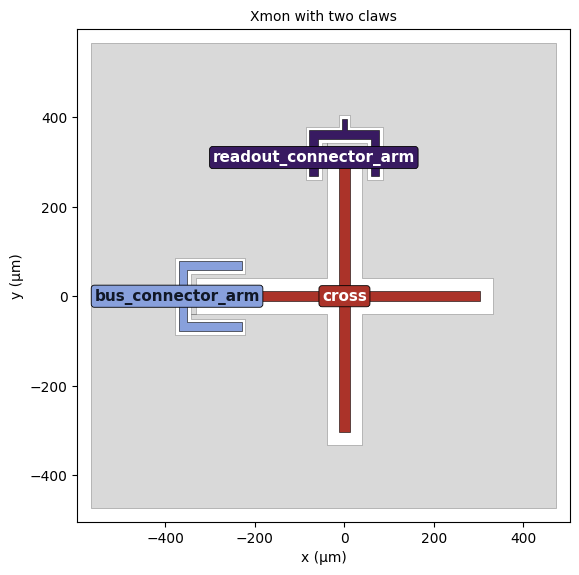

In [45]:
xmon_layout = prepare_layout(xmon_gds)
xmon_names = name_conductors(xmon_design, xmon_layout)
xmon_layout.plot(labels=xmon_names, title="Xmon with two claws");

And a third one that is much bigger: a five-qubit lattice from the examples that ship with this tutorial. It has 34 conductors plus ground, so it is a $35 \times 35$ matrix with 595 mutual capacitances.

34 conductors plus ground


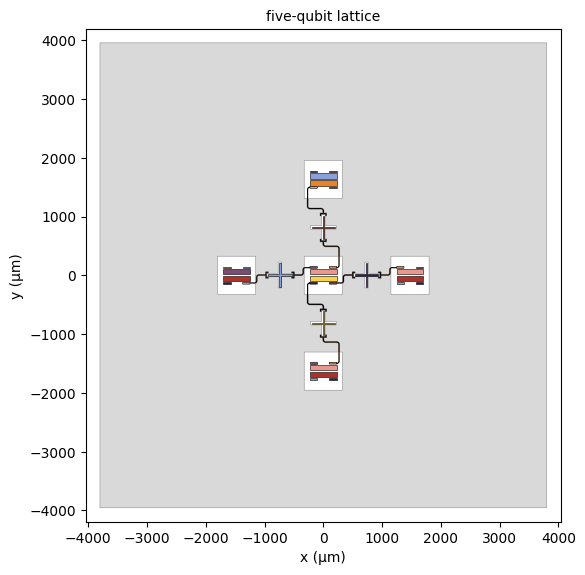

In [46]:
lattice_gds = Path("data/tutorial11/lattice_5q.gds")
lattice_layout = prepare_layout(lattice_gds)
print(len(lattice_layout.names), "conductors plus ground")
lattice_layout.plot(labels=False, title="five-qubit lattice");

### Ground and conductors on one layer

Many layout tools draw the ground plane and the conductors on the same GDS layer. Pass that layer as both `ground_layers` and `conductor_layers` (a file with a single metal layer is handled the same way with the defaults): the metal is split into connected pieces and the ground is picked automatically, with a warning. The conductors are numbered in file order and the detected ground comes last; conductor piece k is named Ck everywhere, so the names are those of the two-layer file. `inspect_layout` shows the pick before you predict: the reason, a confidence and a figure with every piece numbered. Let's move the Xmon's ground and conductors onto layer 2/0 and look.

ground = piece [4] (confidence high): it encloses every other piece (they sit in its openings)


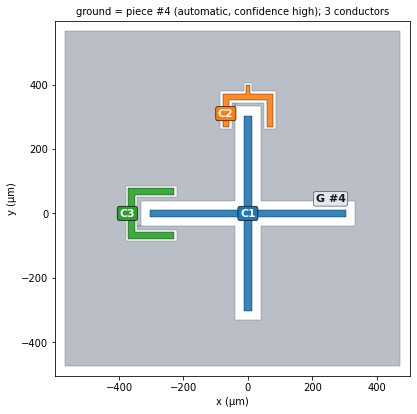

In [47]:
import gdstk

from squadds.ml.capacitance import inspect_layout

lib = gdstk.read_gds(str(xmon_gds))
for cell in lib.cells:
    for poly in cell.polygons:
        if (poly.layer, poly.datatype) in [(1, 0), (1, 10)]:
            poly.layer, poly.datatype = 2, 0
xmon_one_layer = work / "xmon_one_layer.gds"
lib.write_gds(str(xmon_one_layer), max_points=8190)

info = inspect_layout(xmon_one_layer, ground_layers=[(2, 0)], conductor_layers=[(2, 0)])
print("ground = piece", info["ground_pieces"], f"(confidence {info['confidence']}): {info['reason']}")
info["figure"]

The ground is the piece that encloses the others, as it should be. Had the pick been wrong, we would pass the right piece numbers with `ground_pieces=[...]` (several pieces make one ground net). The prediction is the same, bit for bit, as from the two-layer file:

In [48]:
one_layer = dict(ground_layers=[(2, 0)], conductor_layers=[(2, 0)], ground_pieces=info["ground_pieces"])
res_one = predictor.predict(xmon_one_layer, **one_layer)
print("identical to the two-layer file:", np.array_equal(res_one.matrix_fF, predictor.predict(xmon_gds).matrix_fF))

identical to the two-layer file: True


## Batch prediction and threads

`predict` also takes a list of layouts and returns a list of results.

In [49]:
layouts = [star_gds, xmon_gds, lattice_gds]

In [50]:
clear_cache()
t0 = time.perf_counter()
batch = predictor.predict(layouts)
serial_s = time.perf_counter() - t0

In [51]:
pd.DataFrame({
    "layout": [Path(p).name for p in layouts],
    "conductors with ground": [r.n_conductors for r in batch],
    "total (s)": [r.timing_s["total_s"] for r in batch],
    "checks passed": [r.checks["passed"] for r in batch],
})

,layout,conductors with ground,total (s),checks passed
0,multipad_star.gds,5,1.959801,True
1,xmon_two_claws.gds,4,1.590090,True
2,lattice_5q.gds,35,33.522604,True


With `workers=3`, the three layouts are predicted in three processes at once, each with `threads` threads. Starting the processes costs a few seconds, and here the lattice alone takes most of the time, so do not expect miracles on this list: workers pay off for long lists of layouts of similar size.

In [52]:
clear_cache()
t0 = time.perf_counter()
batch_parallel = predictor.predict(layouts, workers=3)
parallel_s = time.perf_counter() - t0
print(f"serial: {serial_s:.1f} s, 3 workers: {parallel_s:.1f} s (wall time, including starting the workers)")

serial: 37.2 s, 3 workers: 40.6 s (wall time, including starting the workers)


In [53]:
same = all(np.allclose(a.matrix_fF, b.matrix_fF, rtol=1e-6, atol=0) for a, b in zip(batch, batch_parallel))
print("identical matrices:", same)

identical matrices: True


For one big layout, it is the threads that help. Let's predict the lattice with 1, 2 and 4 threads, from cold caches each time.

In [54]:
rows = []
for t in (1, 2, 4):
    clear_cache()
    r = predictor.predict(lattice_gds, threads=t)
    rows.append({"threads": t, "total (s)": r.timing_s["total_s"], "prior (s)": r.timing_s["prior_s"],
                 "network (s)": r.timing_s["network_s"]})
pd.DataFrame(rows).round(2)

,threads,total (s),prior (s),network (s)
0,1,52.32,49.57,0.01
1,2,34.55,32.61,0.01
2,4,22.40,22.26,0.02


On this node (Intel Xeon E5-2640 v4), the 35-conductor lattice takes 52 s with 1 thread, 35 s with 2 and 22 s with 4. Nearly all of it is the field solve of the extrapolated physics prior; the networks take about 10 ms.

## From a matrix to a charging energy

Let's put the Xmon's matrix to work. With our names on it:

In [55]:
res_xmon = batch[1]
Cx = res_xmon.to_dataframe().rename(index=xmon_names, columns=xmon_names)
Cx.round(3)

,ground,cross,readout_connector_arm,bus_connector_arm
ground,330.189,-145.438,-59.351,-72.298
cross,-145.438,152.084,-1.874,-2.803
readout_connector_arm,-59.351,-1.874,61.853,-0.036
bus_connector_arm,-72.298,-2.803,-0.036,75.812


The charging energy of the cross depends on what the claws are connected to. Two textbook limits:

- the claws are held at ground (a low-impedance line): $E_C = \frac{e^2}{2 C_\Sigma}$ with $C_\Sigma = C_{\rm cross, cross}$, the diagonal entry,
- the claws are floating islands: $E_C = \frac{e^2}{2} (C^{-1})_{\rm cross, cross}$ with the inverse of the full signal block.

Both need the full matrix row of the cross, and the second needs every entry.

In [56]:
from scipy.constants import e, h

signal = Cx.drop(index="ground", columns="ground")
i = list(signal.index).index("cross")
EC_grounded_MHz = e**2 / (2 * signal.iloc[i, i] * 1e-15) / h / 1e6
EC_floating_MHz = e**2 / 2 * np.linalg.inv(signal.to_numpy() * 1e-15)[i, i] / h / 1e6
print(f"E_C/h = {EC_grounded_MHz:.1f} MHz (claws grounded), {EC_floating_MHz:.1f} MHz (claws floating)")

E_C/h = 127.4 MHz (claws grounded), 127.5 MHz (claws floating)


The two limits differ by only about 0.1 MHz here because the claws couple weakly to the cross (1.9 fF and 2.8 fF, against a self capacitance of 152 fF). On a design with strong couplers they would not, and only the full matrix tells you which case you are in.

## A prediction as a SQuADDS_DB row

`to_sim_results` returns the `sim_results` shape of the capacitance rows of `SQuADDS_DB`: positive magnitudes `<a>_to_<b>` (the self capacitances on the diagonal, the ground named `ground`), the signed Maxwell matrix as `C_<a>_<b>`, and the units. This means the calculators in `squadds.calcs` take an ML prediction the same way they take a Q3D simulation.

In [57]:
sim = res.to_sim_results(names={k: v for k, v in star_names.items() if k != "G"})
pd.Series({k: v for k, v in sim.items() if k != "maxwell_matrix"})

star_to_star         70.778732
star_to_pad_0         9.386298
star_to_pad_1         9.363807
star_to_pad_3         9.562051
star_to_ground       40.697727
pad_0_to_pad_0        29.27846
pad_0_to_pad_1        0.594011
pad_0_to_pad_3        0.119355
pad_0_to_ground      18.813667
pad_1_to_pad_1       29.247648
pad_1_to_pad_3        0.118482
pad_1_to_ground      18.799917
pad_3_to_pad_3       29.215242
pad_3_to_ground       19.06064
ground_to_ground    131.928726
units                       fF
dtype: object

In [58]:
pd.Series(sim["maxwell_matrix"]).head(8)

C_G_G           131.928726
C_G_star        -40.697727
C_G_pad_0       -18.813667
C_G_pad_1       -18.799917
C_G_pad_3       -19.060640
C_star_G        -40.697727
C_star_star      70.778732
C_star_pad_0     -9.386298
dtype: float64

## From the command line

Everything above is also one shell command away:

```bash
squadds-ml predict my_chip.gds                      # QCap, CSV to stdout
squadds-ml predict a.gds b.gds --workers 2          # several files
squadds-ml predict my_chip.gds --model QCap-Fast --format json
```

Let's try it on our star with `QCap-Fast`.

In [59]:
!squadds-ml predict tutorial11_files/multipad_star.gds --model QCap-Fast

# tutorial11_files/multipad_star.gds: QCap-Fast, 1.25 s (2 threads, Intel(R) Xeon(R) CPU E5-2640 v4 @ 2.40GHz, 20 CPUs, Linux x86_64)
# warning: Use QCap-Fast only for quick screening of the component families it was trained on (interdigital, paddle, concentric, star, multipad star, Xmon, TransmonPocket, shielded concentric, two-net, random, procedurally generated and synthetic campaign layouts). On new designs of a trained family (B5) it was worse than the physics alone, 3.175 % (MAE 0.583 / RMSE 0.824 fF) against 1.765 % (0.275 / 0.376 fF), and the paper's version of it was worse than the physics alone on a held-out family too, 3.11 % (0.533 / 0.633 fF) against 1.55 % (0.166 / 0.205 fF). Use QCap for anything that matters.


,G,C1,C2,C3,C4
G,131.876,-41.3814,-18.813,-18.8125,-19.0306
C1,-41.3814,70.7831,-9.11886,-9.13512,-9.2147
C2,-18.813,-9.11886,29.016,-0.552948,-0.113256
C3,-18.8125,-9.13512,-0.552948,29.0319,-0.113031
C4,-19.0306,-9.2147,-0.113256,-0.113031,28.8689


## The geometric embedding

A network cannot read polygons directly. The same metal can be drawn in many ways in a GDS, and a network needs inputs of a fixed size that change smoothly when the geometry does. So before the networks see a layout, we turn it into a **geometric embedding** (`planar-capacitance-graph-v1`), a graph with one vector per conductor and one per pair of conductors:

- 60 shape and context features per conductor (its outline, size and surroundings),
- 42 features per pair of conductors (how close they come and how their separations are distributed),
- 4 global features of the chip.

It is available on its own in `squadds.layouts`, for example to compare designs or to train your own models.

In [60]:
from squadds.layouts import CAPACITANCE_GRAPH_VERSION, encode_capacitance_graph

In [61]:
emb = encode_capacitance_graph(star_gds)
CAPACITANCE_GRAPH_VERSION, {k: v.shape for k, v in emb.items() if hasattr(v, "shape")}

('planar-capacitance-graph-v1',
 {'node_features': (5, 60),
  'pair_features': (10, 42),
  'pairs': (10, 2),
  'global_features': (4,)})

In [62]:
nodes = pd.DataFrame(emb["node_features"], index=[star_names[n] for n in emb["names"]],
                     columns=emb["node_feature_names"])
nodes.iloc[:, :8].round(3)

,compactness,fourier_00,fourier_01,fourier_02,fourier_03,fourier_04,fourier_05,fourier_06
ground,0.696,0.004,0.032,0.121,0.094,0.391,0.007,0.169
star,0.360,0.000,0.000,0.618,0.000,0.000,0.000,0.000
pad_0,0.393,0.021,0.159,0.099,0.096,0.207,0.203,0.150
pad_1,0.393,0.021,0.159,0.099,0.096,0.207,0.203,0.149
pad_3,0.393,0.021,0.159,0.100,0.096,0.207,0.204,0.149


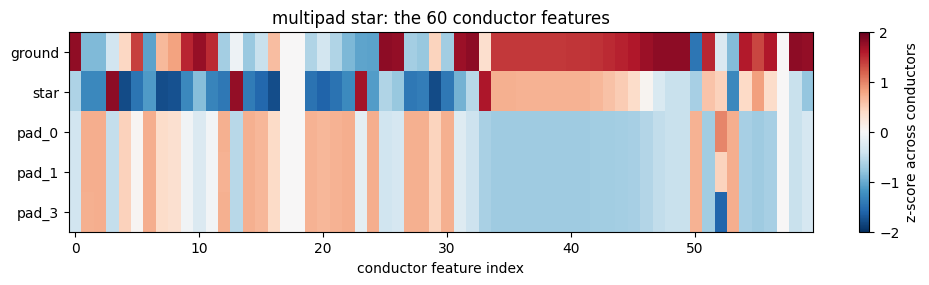

In [63]:
z = (nodes - nodes.mean()) / (nodes.std() + 1e-12)
fig, ax = plt.subplots(figsize=(12, 2.6))
im = ax.imshow(z.to_numpy(), aspect="auto", cmap="RdBu_r", vmin=-2, vmax=2)
ax.set_yticks(range(len(z)), z.index)
ax.set_xlabel("conductor feature index")
fig.colorbar(im, label="z-score across conductors")
ax.set_title("multipad star: the 60 conductor features");

## Next Steps...

How do you know the model is good enough for **your** designs? In [Tutorial 14](https://lfl-lab.github.io/SQuADDS/source/tutorials/Tutorial-14_Training_on_Your_Own_Designs.html), we will score it against Q3D simulations of our own designs and learn when (and how) to train on them.

## License

<div style='width: 100%; background-color:#3cb1c2;color:#324344;padding-left: 10px; padding-bottom: 10px; padding-right: 10px; padding-top: 5px'>
    <h3>This code is a part of SQuADDS</h3>
    <p>Developed by Sadman Ahmed Shanto</p>
    <p>This tutorial is written by Sadman Ahmed Shanto and Claude Opus 5.5</p>
    <p>&copy; Copyright Sadman Ahmed Shanto & Eli Levenson-Falk 2026.</p>
    <p>This code is licensed under the MIT License. You may<br> obtain a copy of this license in the LICENSE.txt file in the root directory<br> of this source tree.</p>
    <p>Any modifications or derivative works of this code must retain this<br>copyright notice, and modified files need to carry a notice indicating<br>that they have been altered from the originals.</p>
</div>